# Optimal Treatment Period Derivation

In [1]:
import os
import sys
import json
import numpy as np
import scipy as sc
import seaborn as sns
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import MaxNLocator
from matplotlib.colors import to_rgb
from matplotlib.patches import Rectangle

sys.path.append("../utils")
from myUtils import convert_ode_parameters,  calc_critical_treatment_threshold, calc_critical_treatment_interval,  TreatmentListToTS, ExtractTreatmentFromDf
from odeModels import LotkaVolterraModel
from plotUtils import plot_simulation

In [2]:
# Defaults for plotting
plt.style.use(["classic", "../paper_figures/paper.mplstyle"])
plt.rcParams['font.size'] = '18'

colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

odeParamDic = convert_ode_parameters(n0=0.75, rFrac=0.001, cost=0, turnover=0)

In [3]:
def convert_to_rgb_grayscale(col):
    rgb_col = to_rgb(col)
    return tuple([(0.2989 * rgb_col[0]) + (0.5870 * rgb_col[1]) + (0.1140 * rgb_col[2]) for _ in range(3)])

def redistribute_rgb(col):
    r, g, b = col
    threshold = 1 
    m = max(r, g, b)
    if m <= threshold:
        return r, g, b
    total = r + g + b
    if total >= 3 * threshold:
        return threshold, threshold, threshold
    x = (3 * threshold - total) / (3 * m - total)
    gray = threshold - x * m
    return (gray + x * r), (gray + x * g), (gray + x * b)

/var/folders/by/xwl2vmrj5dl9941qxr6lr2t4002mml/T/ipykernel_66994/1307944024.py:16: UserWarning: FixedFormatter should only be used together with FixedLocator
  plt.gca().set_xticklabels([''] + list(colors.keys()));


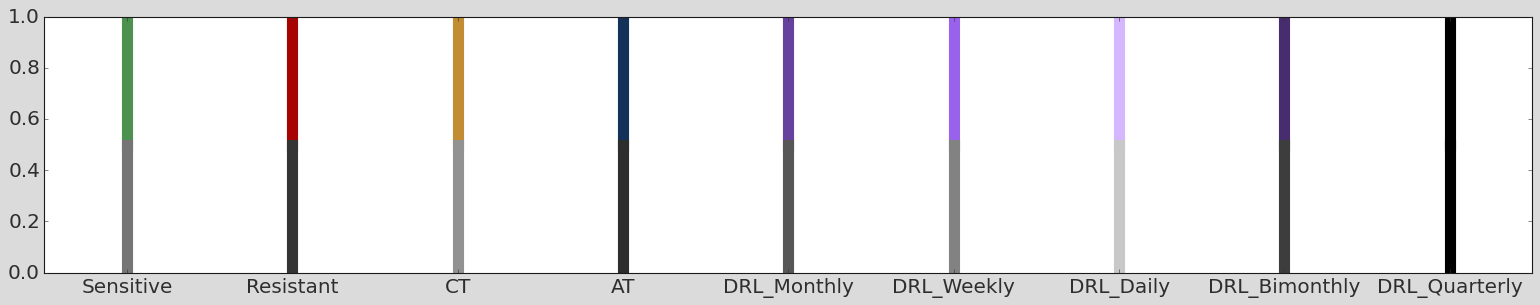

In [4]:
# Defaults for plotting
colors = {'Sensitive': '#4c9150', 'Resistant': '#a80303', 'CT':'#c28d32' , 'AT':'#0044AA' ,'DRL_Monthly':'#66419e'}

colors['DRL_Weekly'] = redistribute_rgb(tuple([1.5 * x for x in to_rgb(colors['DRL_Monthly'])]))
colors['DRL_Daily'] = redistribute_rgb(tuple([2.0 * x for x in to_rgb(colors['DRL_Monthly'])]))

colors['DRL_Bimonthly'] = redistribute_rgb(tuple([0.7 * x for x in to_rgb(colors['DRL_Monthly'])]))
colors['DRL_Quarterly'] = redistribute_rgb(tuple([0 * x for x in to_rgb(colors['DRL_Monthly'])]))

fig, ax = plt.subplots(1, 1, figsize=(24, 4))
for i, col in enumerate(colors.values()):
    plt.axvline(i+1, 0.5, 1, color = col, linewidth=10)
    plt.axvline(i+1, 0, 0.5, color = convert_to_rgb_grayscale(col), linewidth=10)
plt.xlim(0.5, len(colors.values()) + 0.5)
ax.xaxis.set_major_locator(MaxNLocator(integer=True))
plt.gca().set_xticklabels([''] + list(colors.keys()));

## Panel A - shows the concept of premature failiure in analytic patients

In [5]:
trainingDataDf = pd.read_csv("../patients/fitProgressionDf.csv", index_col=0)
trainingDataDf = trainingDataDf[trainingDataDf.PatientId==25]
modelParamDic = convert_ode_parameters(trainingDataDf['n0'].values[0],trainingDataDf['fR'].values[0],
                                     trainingDataDf['Cost'].values[0],trainingDataDf['Turnover'].values[0])


In [6]:
model_28 = LotkaVolterraModel(method='RK45')
model_28.SetParams(**modelParamDic)
model_28.Simulate_AT(atThreshold=0.5, intervalLength=28, t_end=5000);
model_28.Trim(dt=1)
model_28.resultsDf[['TumourSize', 'S', 'R']] /= modelParamDic['n0'];

In [7]:
model_30 = LotkaVolterraModel(method='RK45')
model_30.SetParams(**modelParamDic)
model_30.Simulate_AT(atThreshold=0.5, intervalLength=30, t_end=5000);
model_30.Trim(dt=1)
model_30.resultsDf[['TumourSize', 'S', 'R']] /= modelParamDic['n0'];

In [8]:
print(calc_critical_treatment_interval(n_crit=modelParamDic['n0'], **modelParamDic))
# Failure past 28 days when upper limit is the original tumor size

28.240138155046523


In [9]:
def PlotDrug(dataDf, ax, color, plotDrugAsBar=True, currDrugBarPosition = 1.2, drugBarHeight = 0.2, line_max=None, **kwargs):
    # Generate drug data as time series from list
    drugConcentrationItem = TreatmentListToTS(treatmentList=ExtractTreatmentFromDf(dataDf),
                                                    tVec=dataDf['Time'])
    try:
        drugConcentrationVec += drugConcentrationItem
        max_dose = max(max_dose, np.max(drugConcentrationItem))
    except UnboundLocalError:
        drugConcentrationVec = drugConcentrationItem
        max_dose = np.max(drugConcentrationItem)

    # Plot as bars across top of plot. Cleaner, but can be harder to see alignment with tumour trajectory.
    # Rescale to make it fit within the bar at the top of the plot
    drugConcentrationVec = drugConcentrationVec * drugBarHeight + currDrugBarPosition
    line_max = dataDf['Time'].max() if line_max is None else line_max
    ax.fill_between(x=dataDf['Time'], y1=currDrugBarPosition, y2=drugConcentrationVec, linewidth=0.0,
                     alpha=0.5, step="post", label="Drug Concentration", color=color, **kwargs)
    ax.hlines(xmin=dataDf['Time'].min(), xmax=line_max, y=currDrugBarPosition, linewidth=3, color="black")
    ax.hlines(xmin=dataDf['Time'].min(), xmax=line_max, y=currDrugBarPosition + drugBarHeight, linewidth=3, color="black")


def Plot_method(df, ax, plot_drug = True, linewidth=5, linestyle='-', drug_limit = None, color='b', **kwargs):
    ax.plot(df['Time'], df['TumourSize'], linewidth=linewidth, linestyle=linestyle, color=color, **kwargs)

    if plot_drug:
        PlotDrug(df, ax, 'k', plotDrugAsBar = True, line_max=drug_limit, currDrugBarPosition = 1.25)
        
    ax.hlines(xmin=0, xmax=max(df['Time']), y=1, linestyles=":", linewidth=6, color='grey')
    ax.hlines(xmin=0, xmax=max(df['Time']), y=1.2, linestyles=":", linewidth=6, color='grey')

    # Format the plot
    ax.set_title(kwargs.get('title', '')); ax.set_ylim(0, 1.4)
    ax.yaxis.get_major_ticks()[-1].set_visible(False); ax.tick_params(right = False, top = False)
    plt.tight_layout()

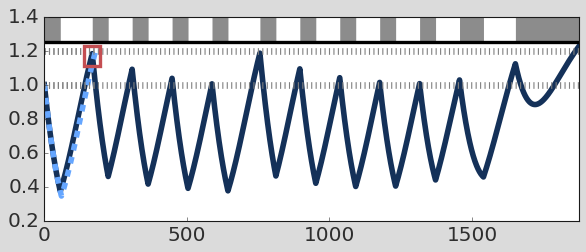

In [34]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(8,3.5))
Plot_method(model_28.resultsDf, ax=ax, color = colors['AT'], linewidth=5)
false_col = redistribute_rgb(tuple([3.3 * x for x in to_rgb(colors['AT'])]))
Plot_method(model_30.resultsDf, ax=ax, color = false_col, plot_drug = False, linestyle = '--', linewidth=5)

# Add the patch to the Axes
ax.add_patch(Rectangle((140, 1.11), 55, 0.12, linewidth=3, edgecolor='r', facecolor='none', zorder=10));


ax.set_xlim(0, 1875); ax.set_ylim(0.2, 1.4)
plt.savefig("figures/SI_AT_failure.pdf")

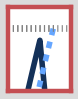

In [43]:
fix, ax = plt.subplots(1,1,figsize=(2.1,2))
Plot_method(model_28.resultsDf, ax=ax, color = colors['AT'])
false_col = redistribute_rgb(tuple([3.3 * x for x in to_rgb(colors['AT'])]))
Plot_method(model_30.resultsDf, ax=ax, color = false_col, plot_drug = False, linestyle = '--')

ax.set_ylim(1.11, 1.23); ax.set_xlim(140, 195)
plt.gca().set_xticklabels([]); plt.gca().set_yticklabels([]);
ax.xaxis.set_ticks_position('none'); ax.yaxis.set_ticks_position('none') ;
for label in ['bottom', 'top', 'right', 'left']:
    ax.spines[label].set_color('r')
ax.tick_params(axis='x', colors='w')
plt.setp(ax.spines.values(), linewidth=4);
plt.savefig("figures/SI_inset_AT_failure.pdf")

## Panel B- Define concept of critical threshold

In [12]:
def PlotDrug(dataDf, ax, color, plotDrugAsBar=True, currDrugBarPosition = 1.2, drugBarHeight = 0.2, line_max=None, **kwargs):
    # Generate drug data as time series from list
    drugConcentrationItem = TreatmentListToTS(treatmentList=ExtractTreatmentFromDf(dataDf),
                                                    tVec=dataDf['Time'])
    try:
        drugConcentrationVec += drugConcentrationItem
        max_dose = max(max_dose, np.max(drugConcentrationItem))
    except UnboundLocalError:
        drugConcentrationVec = drugConcentrationItem
        max_dose = np.max(drugConcentrationItem)

    # Plot as bars across top of plot. Cleaner, but can be harder to see alignment with tumour trajectory.
    # Rescale to make it fit within the bar at the top of the plot
    drugConcentrationVec = drugConcentrationVec * drugBarHeight + currDrugBarPosition
    line_max = dataDf['Time'].max() if line_max is None else line_max
    ax.fill_between(x=dataDf['Time'], y1=currDrugBarPosition, y2=drugConcentrationVec, linewidth=0.0,
                     alpha=0.5, step="post", label="Drug Concentration", color=color, **kwargs)
    ax.hlines(xmin=dataDf['Time'].min(), xmax=line_max, y=currDrugBarPosition, linewidth=3, color="black")
    ax.hlines(xmin=dataDf['Time'].min(), xmax=line_max, y=currDrugBarPosition + drugBarHeight, linewidth=3, color="black")


def Plot(df, legend=False, drug_label="Drug Concentration",
         ax=None, linewidth=5, drug_limit = None, **kwargs):
    if ax is None: fig, ax = plt.subplots(1, 1)
    currModelPredictionDf = pd.melt(df, id_vars=['Time'], value_vars=["TumourSize"])
    ax.plot(currModelPredictionDf['Time'], currModelPredictionDf['value'], linewidth=linewidth, **kwargs)

    PlotDrug(df, ax, 'k', plotDrugAsBar = True, currDrugBarPosition = 1.2, drugBarHeight = 0.2, line_max=drug_limit)

    # Format the plot
    ax.set_title(kwargs.get('title', ''))
    # plt.tight_layout()

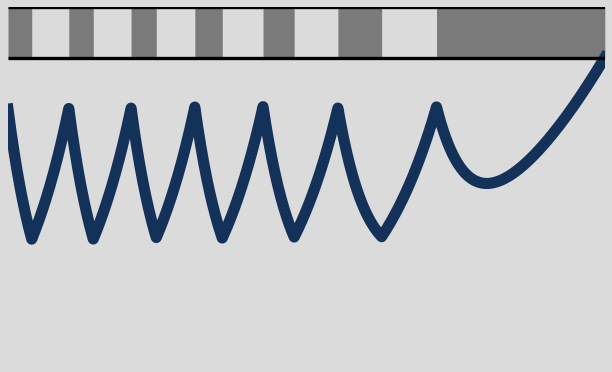

In [13]:
n0, r0 = 0.1, 0.003
cost, turnover = 0.4, 0.4
rs = 0.027  # From literature
t_max = 4000

fig, ax = plt.subplots(1, 1, figsize = (8,5))


model = LotkaVolterraModel(method='RK45', dt = 1)
paramDic = {"Cost": cost, "Turnover": turnover,
            "N0": n0, "R0": r0, "S0": (n0 - r0),
            "rS": rs, "rR": rs * (1-cost),
            "dS": rs * turnover, "dR": rs * turnover,
            'K': 1.5, 'DD': 1.5}
model.SetParams(**paramDic)
model.Simulate_AT(atThreshold=0.5, intervalLength=1, t_end=t_max)
model.resultsDf[['TumourSize', 'S', 'R']] /= paramDic['N0']

Plot(model.resultsDf, ax=ax, legend=False, color = colors['AT'], linewidth=10)
# ax.add_patch(Rectangle((0, 0.5), model.ttp, 0.7, linewidth=0, alpha=0.5, facecolor='k', zorder=0));

# ax.hlines(xmin=0, xmax=model.ttp, y=1.2, linewidth=3, color="black")
# ax.hlines(xmin=0, xmax=model.ttp, y=0.5, linewidth=3, color="black")

ax.set_xticks([]); ax.set_yticks([]); ax.axis('off')
ax.set_xlim(0, model.ttp); ax.set_ylim(0, 1.4); 
ax.tick_params(top=False, right=False)

plt.tight_layout()
plt.savefig("figures/SI_crit_treatment_diagram.pdf")

## Panel C - Critical treatment interval

/Users/80024651/Documents/Moffitt/AT_Benefit_Prediction/paper_figures/../utils/myUtils.py:102: RuntimeWarning: divide by zero encountered in scalar divide
  log_2 = (prog * S0) / (n_crit)
/Users/80024651/Documents/Moffitt/AT_Benefit_Prediction/paper_figures/../utils/myUtils.py:103: RuntimeWarning: invalid value encountered in log
  return (np.log(log_1) / (dS-rS)) + (np.log(log_2) / (rS-dS))


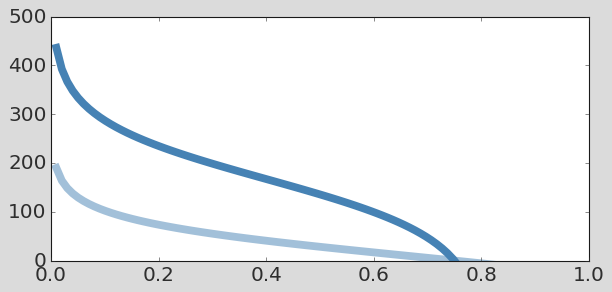

In [14]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(8,4))

n0 = odeParamDic['n0']; rs = odeParamDic['rS']
n_crit_vals = np.linspace(0, 1.2, 100); 

turnover=0.4
tau_high_turnover = [calc_critical_treatment_interval(n_crit=n, S0=n0, K=1.6, rS=rs, dS=(rs*turnover))
               for n in n_crit_vals]
plt.plot(np.linspace(0, 1, 100), tau_high_turnover, linewidth = 7, label = f"$turnover = {turnover}$",
          color='steelblue'); 

turnover=0
tau_low_turnover = [calc_critical_treatment_interval(n_crit=n, S0=n0, K=1.6, rS=rs, dS=(rs*turnover))
              for n in n_crit_vals]
plt.plot(np.linspace(0, 1, 100), tau_low_turnover, linewidth = 7, label = f"$turnover = {turnover}$",
          color='steelblue', alpha=0.5); 



# plt.xlabel("Turnover"); plt.ylabel("Analytic Threshold"); 
# plt.legend(loc=1); 
plt.ylim(bottom=0)
plt.tight_layout(); plt.savefig("figures/SI_analytic_interval.pdf")

/Users/80024651/Documents/Moffitt/AT_Benefit_Prediction/paper_figures/../utils/myUtils.py:102: RuntimeWarning: divide by zero encountered in scalar divide
  log_2 = (prog * S0) / (n_crit)


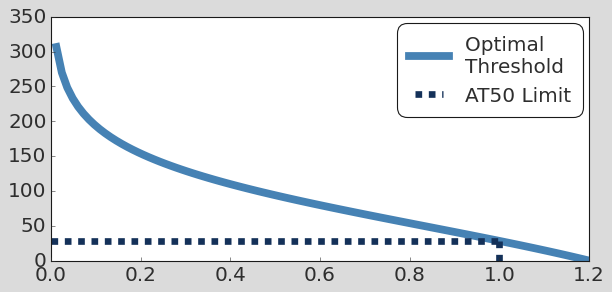

In [15]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(8,4))

n_crit_vals = np.linspace(0, 1.2, 100); 

at_tau = calc_critical_treatment_interval(n_crit=1 * modelParamDic['n0'], **modelParamDic)

tau_high_turnover = [calc_critical_treatment_interval(n_crit=n * modelParamDic['n0'], **modelParamDic)
               for n in n_crit_vals]
plt.plot(n_crit_vals, tau_high_turnover, linewidth = 7, label = 'Optimal \nThreshold', color='steelblue'); 

ax.hlines(xmin=0, xmax=1, y=at_tau, linestyles="--", linewidth=6, color=colors['AT'], label = 'AT50 Limit')
ax.vlines(ymin=0, ymax=at_tau, x=1, linestyles="--", linewidth=6, color=colors['AT'])

ax.tick_params(right = False, top = False)
plt.gca().legend(loc=1, fontsize=18, numpoints=1).get_frame().set_boxstyle('Round', pad=0.2, rounding_size=0.5)
plt.ylim(bottom=0)
plt.tight_layout(); plt.savefig("figures/SI_analytic_interval.pdf")

## TTP prediction plots

### Panel I

In [16]:
predictionParams = modelParamDic.copy()
predictionParams['K'] = 3
predictionParams['R0'] = 0.003

In [17]:
model_s0 = LotkaVolterraModel(method='RK45', dt=1)
s0_params = predictionParams.copy(); s0_params['S0'] = 0
model_s0.SetParams(**s0_params)
model_s0.Simulate([[0, 2000, 1]], t_end=2000)

model_s0.resultsDf[['TumourSize', 'S', 'R']] /= modelParamDic['n0']
df_0 = model_s0.resultsDf[model_s0.resultsDf.R < 1.2]

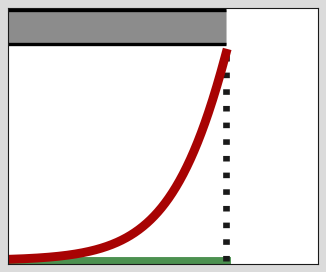

In [18]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(5,4))
# Plot_method(df, ax=ax, color = colors['AT'])
PlotDrug(df_0, ax, 'k', plotDrugAsBar = True, line_max=None, currDrugBarPosition = 1.25)

# for i, (key, col_key) in enumerate(zip(['TumourSize', 'S', 'R', ], ['AT', 'Sensitive', 'Resistant'])):
#     ax.plot(df['Time'], df[key], linewidth=6, linestyle=['-', '--', '--'][i], color=colors[col_key])

for i, (key, col_key) in enumerate(zip(['S', 'R'], ['Sensitive', 'Resistant'])):
    ax.plot(df_0['Time'], df_0[key], linewidth=8, color=colors[col_key], zorder=[-1, 1][i])

ax.vlines(x=max(df_0['Time']), ymin=0, ymax=max(df_0['R']), 
          linestyles=(0,(5,10)), linewidth=6, color='k', zorder=0)

ax.set_xticklabels([]); ax.set_yticklabels([])
ax.tick_params(top=False, right=False, left=False, bottom=False)
ax.set_ylim(-0.02, 1.46); ax.set_xlim(0, 600)
plt.savefig("figures/fig2a_panel1.pdf")

### Panel II

In [19]:
model_sx = LotkaVolterraModel(method='RK45', dt=1)
sx_params = predictionParams.copy(); 
sx_params['rS'] = 0; sx_params['dS'] = 0
model_sx.SetParams(**sx_params)
model_sx.Simulate([[0, 2000, 1]], t_end=2000)

model_sx.resultsDf[['TumourSize', 'S', 'R']] /= modelParamDic['n0']
df_x = model_sx.resultsDf[model_sx.resultsDf.R < 1.2]

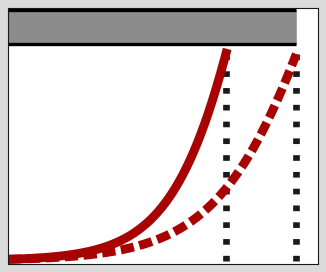

In [20]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(5,4))
PlotDrug(df_x, ax, 'k', plotDrugAsBar = True, line_max=None, currDrugBarPosition = 1.25)

for i, df in enumerate([df_0, df_x]):
    ax.plot(df['Time'], df['R'], linestyle = ['-', (0, (12,5))][i], 
            linewidth=8, color=colors['Resistant'])
    ax.vlines(x=max(df['Time']), ymin=0, ymax=max(df['R']), 
          linestyles=(0,(5.1,10)), linewidth=6, color='k', zorder=0)

ax.set_xticklabels([]); ax.set_yticklabels([])
ax.tick_params(top=False, right=False, left=False, bottom=False)
ax.set_ylim(-0.02, 1.46); ax.set_xlim(0, 600)
plt.savefig("figures/fig2a_panel2.pdf")

### Panel III

30 day threshold is: 0.32


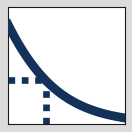

In [21]:
# Inset for panel 3

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(2,2))

tau_values = np.linspace(0, 160, 100)
n_stars = [calc_critical_treatment_threshold(tau=t,**predictionParams)
           / n0 for t in tau_values]
ax.plot(tau_values, n_stars, linewidth = 8, color=colors['AT'], zorder=5); 

threshold = calc_critical_treatment_threshold(tau=30,**predictionParams)
print(f"30 day threshold is: {threshold:.2f}")

val = calc_critical_treatment_interval(n_crit = 0.3 * n0,**predictionParams) 
ax.hlines(xmin=0, xmax=val, y=0.3, linestyles="--", linewidth=6, color=colors['AT'])
ax.vlines(ymin=0, ymax=0.3, x=val, linestyles="--", linewidth=6, color=colors['AT'])

ax.set_xticklabels([]); ax.set_yticklabels([])
ax.tick_params(top=False, right=False, left=False, bottom=False)
ax.set_ylim(0,0.8)
plt.tight_layout(); plt.savefig("figures/fig2a_panel3_inset.pdf")

In [22]:
model_at = LotkaVolterraModel(method='RK45', dt=1)
model_at.SetParams(**predictionParams)
model_at.Simulate_AT(atThreshold=threshold / (predictionParams['n0']), 
                     intervalLength=1, t_end=5000, refSize = predictionParams['n0'],
                     atMethod='Zhang');
model_at.Simulate_AT(atThreshold=threshold / (predictionParams['n0']*1.2), 
                     intervalLength=1, t_end=5000, refSize = predictionParams['n0']*1.2,
                     atMethod='Zhang', tumourSizeWhenProgressed = 1.21);
model_at.Trim(); 


model_at.resultsDf[['TumourSize', 'S', 'R']] /= predictionParams['n0']
df_at = model_at.resultsDf[model_at.resultsDf.R < 1.2]

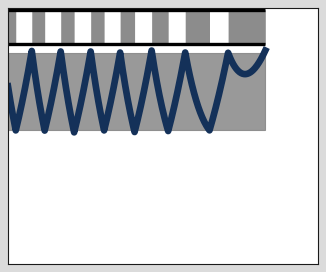

In [23]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(5,4))
PlotDrug(df_at, ax, 'k', plotDrugAsBar = True, line_max=None, currDrugBarPosition = 1.25)

ax.plot(df_at['Time'], df_at['TumourSize'], linewidth=6, color=colors['AT'])

# ax.vlines(x=max(df_0['Time']), ymin=0, ymax=max(df_0['R']), 
#           linestyles=(0,(5,10)), linewidth=6, color='k', zorder=0)

ax.axhspan(ymin=threshold / predictionParams['n0'], ymax=1.2, xmin=0, 
           xmax=max(df_at['Time'])/600, 
           color='gray', alpha=0.8, zorder=-1)

ax.set_xticklabels([]); ax.set_yticklabels([])
ax.tick_params(top=False, right=False, left=False, bottom=False)
ax.set_ylim(-0.02, 1.46); ax.set_xlim(0, 600)
plt.savefig("figures/fig2a_panel3.pdf")

#### Panel 4

In [24]:
model_at2 = LotkaVolterraModel(method='RK45', dt=1)
model_at2.SetParams(**predictionParams)
model_at2.Simulate_AT(atThreshold=1.0* threshold / (predictionParams['n0']), 
                     intervalLength=25, t_end=5000, refSize = predictionParams['n0'],
                     atMethod='Threshold');
model_at2.Trim();

model_at2.resultsDf[['TumourSize', 'S', 'R']] /= modelParamDic['n0']
df_at2 = model_at2.resultsDf[model_at2.resultsDf.R < 1.2]

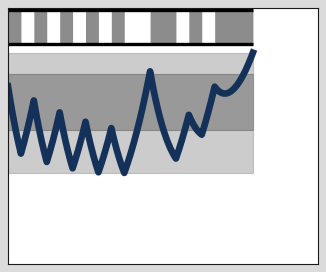

In [25]:
plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(5,4))
PlotDrug(df_at2, ax, 'k', plotDrugAsBar = True, line_max=None, currDrugBarPosition = 1.25)

ax.plot(df_at2['Time'], df_at2['TumourSize'], linewidth=6, color=colors['AT'])

temp_df = df_at2[df_at2.DrugConcentration == 0]
ax.axhspan(ymin=threshold / predictionParams['n0'], ymax=max(temp_df['TumourSize']), 
           xmin=0, xmax=max(df_at2['Time'])/600, 
           color='gray', alpha=0.8, zorder=-1)

ax.axhspan(ymin=max(temp_df['TumourSize']), ymax=1.2, 
           xmin=0, xmax=max(df_at2['Time'])/600, 
           color='gray', alpha=0.4, zorder=-1)

ax.axhspan(ymin=min(temp_df['TumourSize']), 
           ymax=threshold / predictionParams['n0'], 
           xmin=0, xmax=max(df_at2['Time'])/600, 
           color='gray', alpha=0.4, zorder=-1)

ax.set_xticklabels([]); ax.set_yticklabels([])
ax.tick_params(top=False, right=False, left=False, bottom=False)
ax.set_ylim(-0.02, 1.46); ax.set_xlim(0, 600)
plt.savefig("figures/fig2a_panel4.pdf")

(0.0, 2000.0)

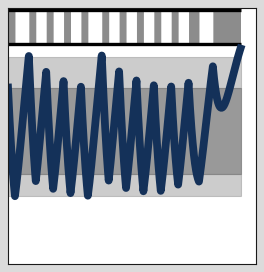

In [26]:
df_at2 = model_28.resultsDf

plt.rcParams['font.size'] = '18'
fig, ax = plt.subplots(1,1,figsize=(4,4))
PlotDrug(df_at2, ax, 'k', plotDrugAsBar = True, line_max=None, currDrugBarPosition = 1.25)

ax.plot(df_at2['Time'], df_at2['TumourSize'], linewidth=7, color=colors['AT'])

# ax.vlines(x=max(df_0['Time']), ymin=0, ymax=max(df_0['R']), 
#           linestyles=(0,(5,10)), linewidth=6, color='k', zorder=0)

ax.axhspan(ymin=0.5, ymax=1, xmin=0, 
           xmax=max(df_at2['Time'])/2000, 
           color='gray', alpha=0.8, zorder=-1)

temp_df = df_at2[df_at2.DrugConcentration == 0]
ax.axhspan(ymin=1, ymax=max(temp_df['TumourSize']), 
           xmin=0, xmax=max(df_at2['Time'])/2000, 
           color='gray', alpha=0.4, zorder=-1)

ax.axhspan(ymin=min(temp_df['TumourSize']), ymax=0.5, 
           xmin=0, xmax=max(df_at2['Time'])/2000, 
           color='gray', alpha=0.4, zorder=-1)

ax.set_xticklabels([]); ax.set_yticklabels([])
ax.tick_params(top=False, right=False, left=False, bottom=False)
ax.set_ylim(-0.02, 1.46); ax.set_xlim(0, 2000)
# plt.savefig("figures/figSI2_panel4.pdf")